In [1]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,export_text
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

TASK 1

No of Samples 178
No of Features: 13
Feature Names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
No of Classes: 3
knn : accuracy : 94.44%
dtree : accuracy : 96.3%
rforest : accuracy : 100.0%


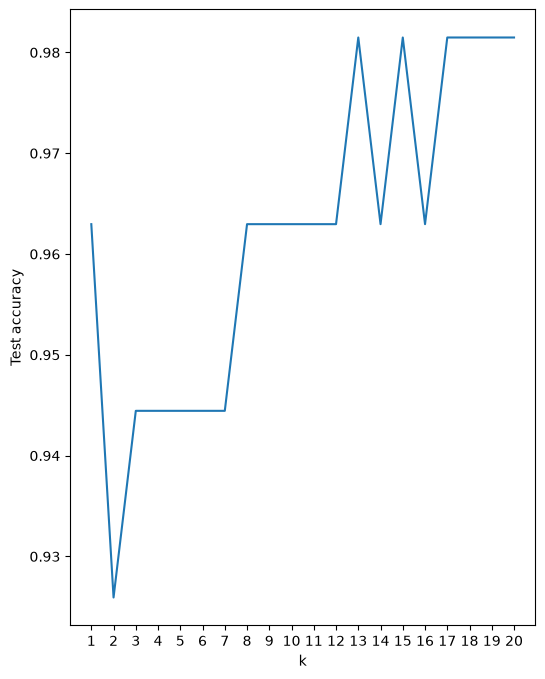

Best k: 13
Accuracy: 0.9814814814814815


In [2]:
from sklearn.datasets import load_wine

data= load_wine()
x=data.data
y=data.target

print(f"No of Samples {x.shape[0]}\nNo of Features: {x.shape[1]}\nFeature Names: {data.feature_names}")
print("No of Classes:", len(data.target_names))

xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.30,random_state=42,stratify=y)
scaler=StandardScaler()
xscaled = scaler.fit_transform(xtrain)
xtscaled= scaler.transform(xtest)

models = {
    "knn": KNeighborsClassifier(5),
    "dtree": DecisionTreeClassifier(max_depth=4,random_state=42),
    "rforest":RandomForestClassifier(n_estimators=100,random_state=42)
}

for name, m in models.items():
    m.fit(xscaled,ytrain)
    print(f"{name} : accuracy : {round(accuracy_score(ytest,m.predict(xtscaled)),4)*100}%")

acclist=[]
for x in range(1,21):
    k = KNeighborsClassifier(x)
    k.fit(xscaled,ytrain)
    acclist.append(k.score(xtscaled,ytest))

fig ,ax = plt.subplots(figsize=(6,8))
ax.plot(range(1,21),acclist)

ax.set_xlabel("k")
ax.set_ylabel("Test accuracy")
ax.set_xticks(range(1, 21))
plt.show()

best_k = np.argmax(acclist) + 1
print("Best k:", best_k)
print("Accuracy:", acclist[best_k - 1])


TASK 2

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report

data = load_breast_cancer()
x = data.data
y = data.target

print("Classes:", data.target_names)  

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

dtree = DecisionTreeClassifier(max_depth=5, random_state=42)
dtree.fit(xtrain, ytrain)
ypred = dtree.predict(xtest)


def confusion(y_true, y_pred):
    # Treat malignant (0) as the positive class
    TP = sum(1 for t, p in zip(y_true, y_pred) if t == 0 and p == 0)
    TN = sum(1 for t, p in zip(y_true, y_pred) if t == 1 and p == 1)
    FP = sum(1 for t, p in zip(y_true, y_pred) if t == 1 and p == 0)
    FN = sum(1 for t, p in zip(y_true, y_pred) if t == 0 and p == 1)
    return TP, TN, FP, FN


def precision(TP, FP):
    return TP / (TP + FP) if TP + FP != 0 else 0


def recall(TP, FN):
    return TP / (TP + FN) if TP + FN != 0 else 0


def f1(prec, rec):
    return 2 * prec * rec / (prec + rec) if prec + rec != 0 else 0


TP, TN, FP, FN = confusion(ytest, ypred)
prec = precision(TP, FP)
rec = recall(TP, FN)
f1_score = f1(prec, rec)
accuracy = (TP + TN) / len(ytest)

print(f"TP = {TP}, TN = {TN}, FP = {FP}, FN = {FN}")
print(f"Accuracy  = {accuracy:.4f}")
print(f"Precision = {prec:.4f}")
print(f"Recall    = {rec:.4f}")
print(f"F1        = {f1_score:.4f}")

print("\nSklearn confusion matrix (labels ordered [0, 1]):")
print(confusion_matrix(ytest, ypred, labels=[0, 1]))

print("\nSklearn classification report:")
print(classification_report(ytest, ypred, target_names=data.target_names))

Classes: ['malignant' 'benign']
TP = 39, TN = 66, FP = 6, FN = 3
Accuracy  = 0.9211
Precision = 0.8667
Recall    = 0.9286
F1        = 0.8966

Sklearn confusion matrix (labels ordered [0, 1]):
[[39  3]
 [ 6 66]]

Sklearn classification report:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



Recall is the most important metric for cancer detection. It measures how many actual cancer patients are correctly identified by the model. A low recall means some cancer patients may be incorrectly classified as healthy. Missing a cancer patient can be very dangerous because they may not receive treatment on time. Therefore, we should aim for high recall.

TASK 3

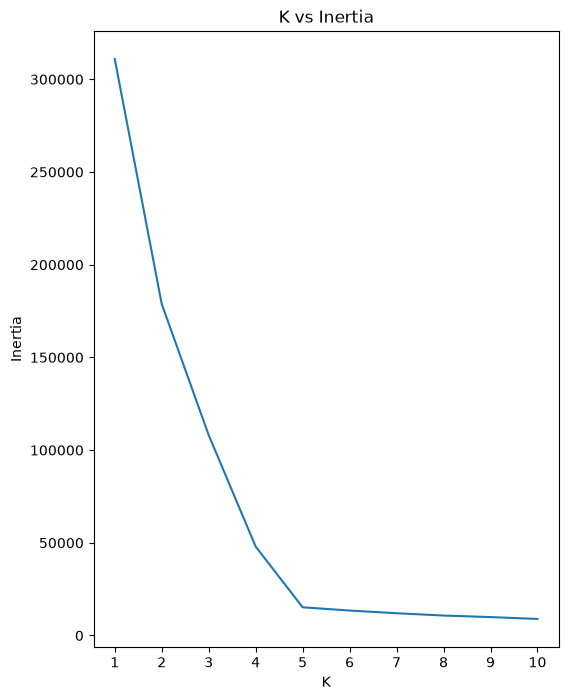

In [4]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

x, _ = make_blobs(n_samples=200, centers=[[25, 20], [25, 80], [55, 50], [85, 20], [85, 80]],
cluster_std=6, random_state=3)

intertia=[]

for k in range(1,11):
    km=KMeans(n_clusters=k,n_init=10,random_state=42).fit(x)
    intertia.append(round(km.inertia_,1))

fig,ax =plt.subplots(figsize=(6,8))
ax.plot(range(1,11),intertia)
ax.set_xlabel("K")
ax.set_ylabel("Inertia")
ax.set_title("K vs Inertia")
ax.set_xticks(range(1,11))


Cluster 0: High income, low spending
  Customers: 40
  Centroid: income = 86.5 thousand, spending score = 20.0
Cluster 1: Middle income, moderate spending
  Customers: 40
  Centroid: income = 55.3 thousand, spending score = 50.6
Cluster 2: Low income, high spending
  Customers: 40
  Centroid: income = 23.6 thousand, spending score = 80.8
Cluster 3: Low income, low spending
  Customers: 40
  Centroid: income = 24.6 thousand, spending score = 19.6
Cluster 4: High income, high spending
  Customers: 40
  Centroid: income = 85.0 thousand, spending score = 78.6


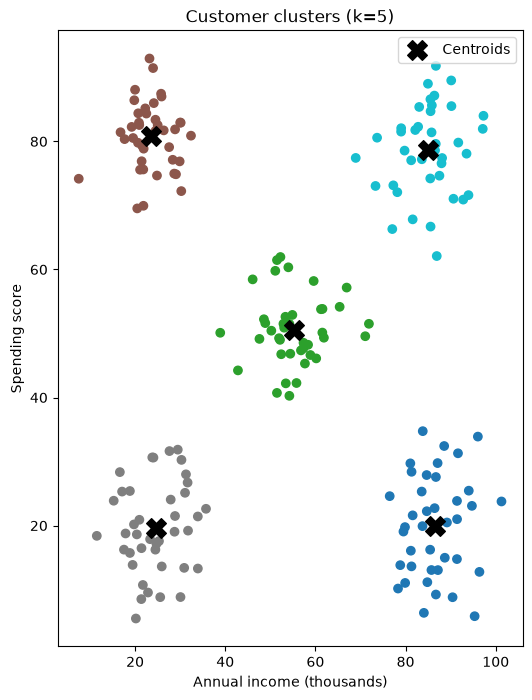

In [5]:

kme= KMeans(n_clusters=5,n_init=10,random_state=42)
labels = kme.fit_predict(x)
centroids =kme.cluster_centers_

for i in range(5):
    count = (labels == i).sum()
    income, spending = centroids[i]

    if income < 40:
        income_name = "Low income"
    elif income < 70:
        income_name = "Middle income"
    else:
        income_name = "High income"

    if spending < 35:
        spending_name = "low spending"
    elif spending < 65:
        spending_name = "moderate spending"
    else:
        spending_name = "high spending"

    name = f"{income_name}, {spending_name}"

    print(f"Cluster {i}: {name}")
    print(f"  Customers: {count}")
    print(f"  Centroid: income = {income:.1f} thousand, "
          f"spending score = {spending:.1f}")


fig,dx =plt.subplots(figsize=(6,8))
dx.scatter(x[:,0],x[:,1],c=labels,cmap="tab10")
dx.scatter(
    centroids[:, 0], centroids[:, 1],
    c="black", marker="X", s=200, label="Centroids"
)

dx.set_xlabel("Annual income (thousands)")
dx.set_ylabel("Spending score")
dx.set_title("Customer clusters (k=5)")
dx.legend()
plt.show()

TASK 4


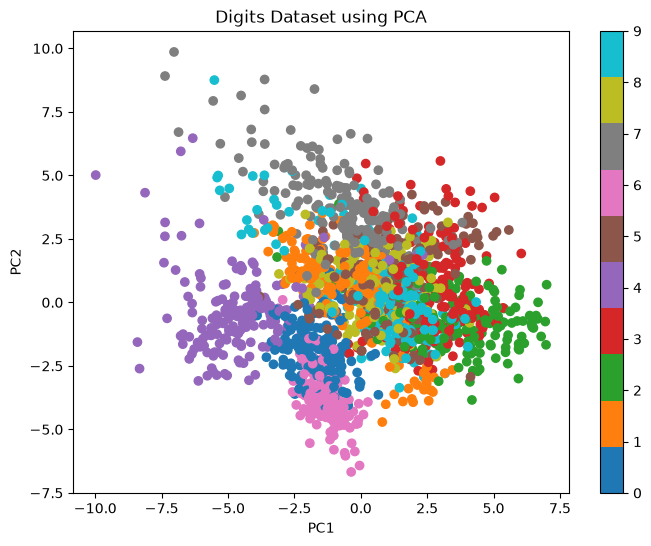

Components required for 95% variance: 40

Original Features
Accuracy: 0.9861111111111112
Training Time: 0.0007269382476806641
Prediction Time: 0.008770942687988281

PCA 95% Features
Accuracy: 0.975
Training Time: 0.0009484291076660156
Prediction Time: 0.009285449981689453


In [6]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
import time

digits = load_digits()

X = digits.data
y = digits.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Digits Dataset using PCA")
plt.colorbar()
plt.show()

pca95 = PCA(n_components=0.95)
X_95 = pca95.fit_transform(X_scaled)

print("Components required for 95% variance:", pca95.n_components_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train_95, X_test_95, y_train_95, y_test_95 = train_test_split(
    X_95, y, test_size=0.2, random_state=42
)

knn1 = KNeighborsClassifier(n_neighbors=5)

start = time.time()
knn1.fit(X_train, y_train)
train_time1 = time.time() - start

start = time.time()
y_pred1 = knn1.predict(X_test)
predict_time1 = time.time() - start

acc1 = accuracy_score(y_test, y_pred1)

knn2 = KNeighborsClassifier(n_neighbors=5)

start = time.time()
knn2.fit(X_train_95, y_train_95)
train_time2 = time.time() - start

start = time.time()
y_pred2 = knn2.predict(X_test_95)
predict_time2 = time.time() - start

acc2 = accuracy_score(y_test_95, y_pred2)

print("\nOriginal Features")
print("Accuracy:", acc1)
print("Training Time:", train_time1)
print("Prediction Time:", predict_time1)

print("\nPCA 95% Features")
print("Accuracy:", acc2)
print("Training Time:", train_time2)
print("Prediction Time:", predict_time2)


Observation:
PCA reduces the number of features while retaining 95% of the variance
It generally reduces training and prediction time with a small change in accuracy